In [11]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
import warnings
warnings.filterwarnings('ignore')

In [12]:
ARQUIVO_DADOS = "/kaggle/input/datasets/juliaduboisas/train-limpo/train_limpo.csv"
COLUNA_TEXTO = "resp_text"
COLUNA_ALVO = "clarity"

df = pd.read_csv(ARQUIVO_DADOS)

mapeamento_classes = {'c1': 0, 'c234': 1, 'c5': 2}
df['label'] = df[COLUNA_ALVO].map(mapeamento_classes)

df = df.dropna(subset=[COLUNA_TEXTO, 'label'])
df['label'] = df['label'].astype(int)
df = df.reset_index(drop=True)

print(f"Total de amostras: {len(df)}")
print(df['label'].value_counts())

Total de amostras: 20092
label
2    6892
1    6853
0    6347
Name: count, dtype: int64


In [13]:
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenizar_dados(exemplos):
    return tokenizer(exemplos['texto'], padding="max_length", truncation=True, max_length=256)

In [14]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

resultados_acuracia = []
todas_predicoes = []
todas_labels = []

# Pesos para o Soft Voting
PESO_LR = 0.15
PESO_SVC = 0.15
PESO_BERT = 0.70

for fold, (train_idx, val_idx) in enumerate(skf.split(df[COLUNA_TEXTO], df['label'])):
    print(f"\n{'='*40}\nIniciando Fold {fold + 1}/3\n{'='*40}")
    
    df_train = df.iloc[train_idx].copy()
    df_val = df.iloc[val_idx].copy()
    
    # ---------------------------------------------------------
    # PREPARAÇÃO TF-IDF (Agora com 20.000 features)
    # ---------------------------------------------------------
    tfidf = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), max_features=20000)
    X_train_tfidf = tfidf.fit_transform(df_train[COLUNA_TEXTO])
    X_val_tfidf = tfidf.transform(df_val[COLUNA_TEXTO])
    
    # ==========================================
    # 1. MODELO: Regressão Logística
    # ==========================================
    print("Treinando Regressão Logística...")
    lr_model = LogisticRegression(C=2, max_iter=1000, class_weight='balanced', random_state=42)
    lr_model.fit(X_train_tfidf, df_train['label'])
    probs_lr = lr_model.predict_proba(X_val_tfidf)
    
    # ==========================================
    # 2. MODELO: LinearSVC Calibrado
    # ==========================================
    print("Treinando LinearSVC...")
    # LinearSVC não solta probabilidade nativamente, CalibratedClassifierCV resolve isso
    svc_base = LinearSVC(C=1, class_weight='balanced', random_state=42)
    svc_model = CalibratedClassifierCV(svc_base, cv=2, method='sigmoid')
    svc_model.fit(X_train_tfidf, df_train['label'])
    probs_svc = svc_model.predict_proba(X_val_tfidf)
    
    # ==========================================
    # 3. MODELO: Fine-tuning Bertimbau
    # ==========================================
    print("Treinando Bertimbau...")
    ds_train = Dataset.from_pandas(df_train[[COLUNA_TEXTO, 'label']].rename(columns={COLUNA_TEXTO: 'texto'}))
    ds_val = Dataset.from_pandas(df_val[[COLUNA_TEXTO, 'label']].rename(columns={COLUNA_TEXTO: 'texto'}))
    
    ds_train = ds_train.map(tokenizar_dados, batched=True)
    ds_val = ds_val.map(tokenizar_dados, batched=True)
    
    ds_train.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
    ds_val.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
    
    bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)
    
    # Hiperparâmetros de treinamento ajustados (learning_rate e warmup adicionados)
    training_args = TrainingArguments(
            output_dir=f'./results_fold_{fold}',
            num_train_epochs=3,
            per_device_train_batch_size=16,
            per_device_eval_batch_size=16,
            learning_rate=2e-5,
            # warmup_ratio=0.1 removido para evitar o erro de compatibilidade
            weight_decay=0.01,
            logging_steps=50,
            eval_strategy="epoch",
            save_strategy="epoch",
            load_best_model_at_end=True,
            report_to="none"
        )

    trainer = Trainer(
        model=bert_model,
        args=training_args,
        train_dataset=ds_train,
        eval_dataset=ds_val,
    )
    
    trainer.train()
    
    logits_bert = trainer.predict(ds_val).predictions
    probs_bert = torch.nn.functional.softmax(torch.tensor(logits_bert), dim=-1).numpy()
    
    # ==========================================
    # 4. WEIGHTED SOFT VOTING
    # ==========================================
    print("Calculando Weighted Soft Voting...")
    probs_ensemble = (probs_lr * PESO_LR) + (probs_svc * PESO_SVC) + (probs_bert * PESO_BERT)
    preds_ensemble = np.argmax(probs_ensemble, axis=1)
    
    acc_fold = accuracy_score(df_val['label'], preds_ensemble)
    print(f"Acurácia do Ensemble no Fold {fold + 1}: {acc_fold:.4f}")
    
    resultados_acuracia.append(acc_fold)
    todas_predicoes.extend(preds_ensemble)
    todas_labels.extend(df_val['label'].tolist())
    
    del bert_model
    del trainer
    torch.cuda.empty_cache()


Iniciando Fold 1/3
Treinando Regressão Logística...
Treinando LinearSVC...
Treinando Bertimbau...


Map:   0%|          | 0/13394 [00:00<?, ? examples/s]

Map:   0%|          | 0/6698 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

Epoch,Training Loss,Validation Loss
1,2.101364,2.087603
2,2.006356,2.094708
3,1.849916,2.119953


... (18 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Calculando Weighted Soft Voting...
Acurácia do Ensemble no Fold 3: 0.4566



RESULTADOS FINAIS - WEIGHTED ENSEMBLE
Acurácia Média: 0.4602 (+/- 0.0038)

Relatório de Classificação Global:
              precision    recall  f1-score   support

          c1       0.48      0.49      0.48      6347
        c234       0.40      0.35      0.37      6853
          c5       0.49      0.54      0.52      6892

    accuracy                           0.46     20092
   macro avg       0.46      0.46      0.46     20092
weighted avg       0.46      0.46      0.46     20092



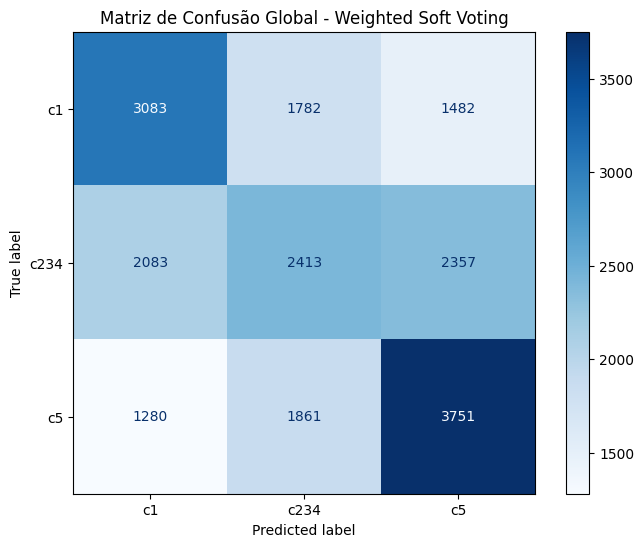

In [15]:
print("\n" + "="*40)
print("RESULTADOS FINAIS - WEIGHTED ENSEMBLE")
print("="*40)
print(f"Acurácia Média: {np.mean(resultados_acuracia):.4f} (+/- {np.std(resultados_acuracia):.4f})")

print("\nRelatório de Classificação Global:")
target_names = ['c1', 'c234', 'c5']
print(classification_report(todas_labels, todas_predicoes, target_names=target_names))

cm = confusion_matrix(todas_labels, todas_predicoes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title('Matriz de Confusão Global - Weighted Soft Voting')
plt.show()